# Davis Southern Women: Women, Events and the Ties Between Them

**Joao De Oliveira**

## Question
What can we infer about the relationships between (1) the 18 women and (2) the 14 social events they attended?

## Data
In the 1930s, Davis, Gardner and Gardner recorded which of 14 social events 18 women in a town in Mississippi attended over about nine months (*Deep South*, 1941). The [dataset](http://vlado.fmf.uni-lj.si/pub/networks/data/Ucinet/davis.dat) is a two-mode (bipartite) network: one set of nodes is the women, the other is the events, and an edge means a woman attended an event.

networkx ships this exact dataset as `nx.davis_southern_women_graph()` (the same 18 × 14 matrix with 89 attendances as the UCINET file), so I load it from there, as in the [networkx example](https://networkx.org/documentation/stable/auto_examples/algorithms/plot_davis_club.html).

## Approach
1. Describe the two-mode network: who attends the most events and which events are biggest.
2. **Project** it onto the women (two women are tied if they attended the same event) and onto the events (two events are tied if they share attendees).
3. Because the simple projections are almost complete, use edge weights (number of shared events or shared women) to find the real structure: communities, central women and central events.
4. Reorder the attendance matrix by community to see the whole picture at once.

## 0. Setup

In [ ]:
import networkx as nx
from networkx.algorithms import bipartite
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

pd.set_option("display.precision", 3)
print("networkx", nx.__version__)

networkx 3.6.1


## 1. Load the two-mode network
`G.graph["top"]` holds the women and `G.graph["bottom"]` the events. I also keep the biadjacency matrix (women × events) as a DataFrame, since it is the clearest view of the raw data.

In [ ]:
G = nx.davis_southern_women_graph()
women = G.graph["top"]
events = G.graph["bottom"]

# short first names to make the plots easier to read
short = {w: w.split()[0] for w in women}

# biadjacency matrix with rows = women, columns = events, 1 = attended
A = pd.DataFrame(bipartite.biadjacency_matrix(G, women, events).toarray(),
                 index=[short[w] for w in women], columns=events)

print(f"Women: {len(women)} | Events: {len(events)} | Attendances (edges): {G.number_of_edges()}")
print(f"Bipartite: {bipartite.is_bipartite(G)} | Connected: {nx.is_connected(G)}")
print(f"Density of the two-mode network: {bipartite.density(G, women):.3f} "
      f"(share of all possible woman-event pairs that happened)")
A

Women: 18 | Events: 14 | Attendances (edges): 89
Bipartite: True | Connected: True
Density of the two-mode network: 0.353 (share of all possible woman-event pairs that happened)


,E1,E2,E3,E4,E5,E6,E7,E8,E9,E10,E11,E12,E13,E14
Evelyn,1,1,1,1,1,1,0,1,1,0,0,0,0,0
Laura,1,1,1,0,1,1,1,1,0,0,0,0,0,0
Theresa,0,1,1,1,1,1,1,1,1,0,0,0,0,0
Brenda,1,0,1,1,1,1,1,1,0,0,0,0,0,0
Charlotte,0,0,1,1,1,0,1,0,0,0,0,0,0,0
Frances,0,0,1,0,1,1,0,1,0,0,0,0,0,0
Eleanor,0,0,0,0,1,1,1,1,0,0,0,0,0,0
Pearl,0,0,0,0,0,1,0,1,1,0,0,0,0,0
Ruth,0,0,0,0,1,0,1,1,1,0,0,0,0,0
Verne,0,0,0,0,0,0,1,1,1,0,0,1,0,0


## 2. Who attends the most, and which events are biggest?
A woman's degree is the number of events she attended. An event's degree is how many of the 18 women came.

Events attended per woman: mean 4.9, range 2-8
Women per event:          mean 6.4, range 3-14


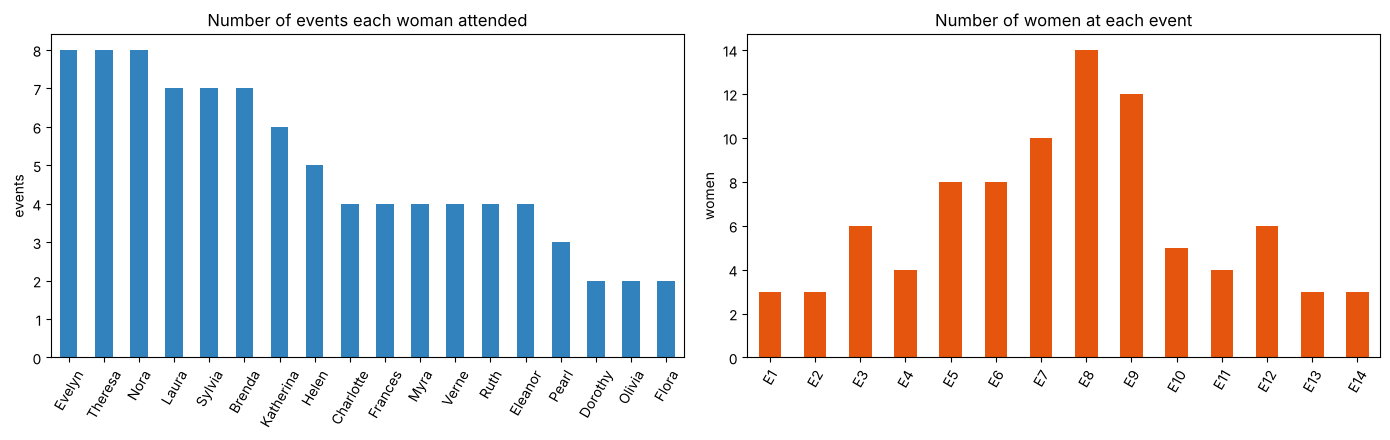

In [ ]:
women_deg = A.sum(axis=1).sort_values(ascending=False)
event_deg = A.sum(axis=0)

print("Events attended per woman: mean %.1f, range %d-%d" % (women_deg.mean(), women_deg.min(), women_deg.max()))
print("Women per event:          mean %.1f, range %d-%d" % (event_deg.mean(), event_deg.min(), event_deg.max()))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
women_deg.plot.bar(ax=axes[0], color="#3182bd")
axes[0].set_title("Number of events each woman attended"); axes[0].set_ylabel("events")
event_deg.plot.bar(ax=axes[1], color="#e6550d")
axes[1].set_title("Number of women at each event"); axes[1].set_ylabel("women")
for ax in axes: ax.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

## 3. The women: projecting onto a woman-woman network
In the projection, two women are linked if they attended at least one event together. The weighted version counts how many events they shared.

In [ ]:
W_simple = bipartite.projected_graph(G, women)
W = bipartite.weighted_projected_graph(G, women)          # weight is number of shared events
W = nx.relabel_nodes(W, short)

print(f"Unweighted projection: {W_simple.number_of_edges()} ties out of {18*17//2} possible "
      f"(density {nx.density(W_simple):.2f})")
deg_simple = dict(W_simple.degree())
print(f"Women tied to all 17 others: {sum(d == 17 for d in deg_simple.values())}")
print(f"Fewest ties: {min(deg_simple.values())}")

weights = pd.Series([d["weight"] for _, _, d in W.edges(data=True)])
print("\nShared events per pair of women (among pairs who share any):")
print(weights.value_counts().sort_index().rename("pairs").to_frame().T)

Unweighted projection: 139 ties out of 153 possible (density 0.91)
Women tied to all 17 others: 7
Fewest ties: 11

Shared events per pair of women (among pairs who share any):
        1   2   3   4  5  6  7
pairs  44  49  22  15  1  7  1


The unweighted projection is almost complete, so "attended something together" says very little: most women crossed paths at least once, mostly at the large events. The weights carry the information. Most pairs share only one or two events, while a few pairs share five or more.

### 3a. Who spends the most time with whom?
The heatmap shows the number of shared events for every pair of women (in the original order of the dataset).

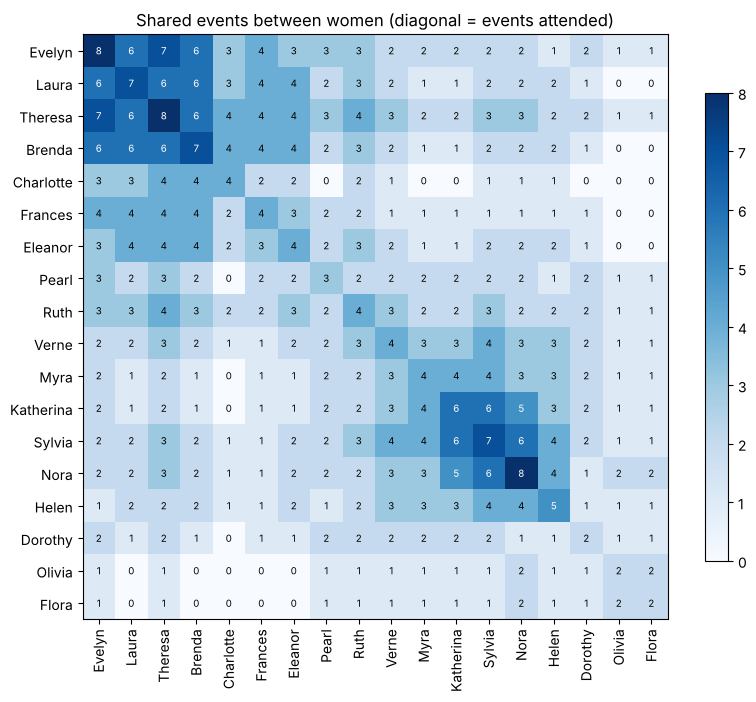

,woman 1,woman 2,shared events
0,Evelyn,Theresa,7
1,Evelyn,Brenda,6
2,Evelyn,Laura,6
3,Theresa,Brenda,6
4,Laura,Brenda,6
5,Sylvia,Nora,6
6,Katherina,Sylvia,6
7,Laura,Theresa,6


In [ ]:
S = A.values @ A.values.T                     # women x women: number of shared events
S = pd.DataFrame(S, index=A.index, columns=A.index)

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(S.values, cmap="Blues")
ax.set_xticks(range(18)); ax.set_xticklabels(S.columns, rotation=90)
ax.set_yticks(range(18)); ax.set_yticklabels(S.index)
for i in range(18):
    for j in range(18):
        ax.text(j, i, S.iat[i, j], ha="center", va="center", fontsize=7,
                color="white" if S.iat[i, j] >= 5 else "black")
ax.set_title("Shared events between women (diagonal = events attended)")
plt.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); plt.show()

# strongest pairs
pairs = [(u, v, d["weight"]) for u, v, d in W.edges(data=True)]
top_pairs = pd.DataFrame(pairs, columns=["woman 1", "woman 2", "shared events"]) \
              .sort_values("shared events", ascending=False).head(8).reset_index(drop=True)
top_pairs

### 3b. Communities among the women
I run Louvain community detection on the weighted projection, so ties built on many shared events count more. A fixed seed makes the result reproducible.

In [ ]:
comms = nx.community.louvain_communities(W, weight="weight", seed=42)
comms = sorted(comms, key=lambda c: min(list(A.index).index(w) for w in c))   # order by dataset position
group_of = {w: i + 1 for i, c in enumerate(comms) for w in c}

for i, c in enumerate(comms, 1):
    members = [w for w in A.index if w in c]
    print(f"Group {i} ({len(members)} women): {', '.join(members)}")
print(f"\nModularity (weighted): {nx.community.modularity(W, comms, weight='weight'):.3f}")

# average shared events within vs between groups
within, between = [], []
for u, v, d in W.edges(data=True):
    (within if group_of[u] == group_of[v] else between).append(d["weight"])
print(f"Average shared events, same group:      {np.mean(within):.2f}")
print(f"Average shared events, different groups: {np.mean(between):.2f}")

Group 1 (8 women): Evelyn, Laura, Theresa, Brenda, Charlotte, Frances, Eleanor, Ruth
Group 2 (10 women): Pearl, Verne, Myra, Katherina, Sylvia, Nora, Helen, Dorothy, Olivia, Flora

Modularity (weighted): 0.152
Average shared events, same group:      2.88
Average shared events, different groups: 1.70


### 3c. Visualizing the women's network
To make the structure visible, I draw only strong ties, meaning pairs who shared at least 3 events. Node color is the Louvain group, node size is the number of events attended, and line width is the number of shared events.

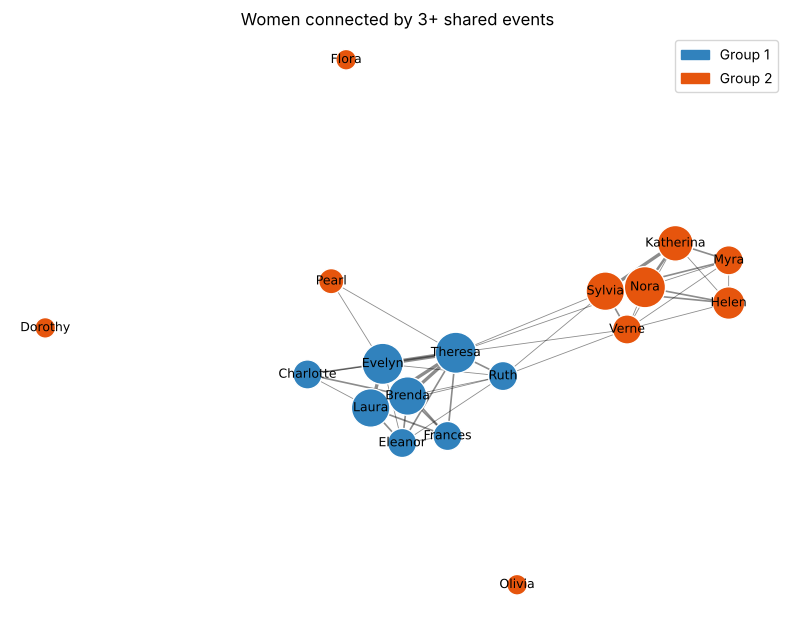

Strong ties: 46 | between groups: 7


In [ ]:
THRESH = 3
W_strong = nx.Graph()
W_strong.add_nodes_from(W.nodes())
W_strong.add_edges_from((u, v, d) for u, v, d in W.edges(data=True) if d["weight"] >= THRESH)

palette = ["#3182bd", "#e6550d", "#31a354", "#756bb1"]
colors = [palette[group_of[w] - 1] for w in W_strong]
sizes = [women_deg[w] * 110 for w in W_strong]
widths = [0.6 * (d["weight"] - THRESH + 1) for _, _, d in W_strong.edges(data=True)]

pos = nx.spring_layout(W_strong, weight="weight", seed=7, k=0.9)
plt.figure(figsize=(10, 7.5))
nx.draw_networkx_edges(W_strong, pos, width=widths, alpha=0.45)
nx.draw_networkx_nodes(W_strong, pos, node_color=colors, node_size=sizes, edgecolors="white")
nx.draw_networkx_labels(W_strong, pos, font_size=9)
plt.legend(handles=[Patch(color=palette[i], label=f"Group {i+1}") for i in range(len(comms))], loc="best")
plt.title(f"Women connected by {THRESH}+ shared events")
plt.axis("off"); plt.show()

print(f"Strong ties: {W_strong.number_of_edges()} | "
      f"between groups: {sum(group_of[u] != group_of[v] for u, v in W_strong.edges())}")

### 3d. Who is central, and who connects the groups?
- **Weighted degree** (strength): total shared events with all other women, which measures how socially active a woman is.
- **Eigenvector centrality** (weighted): high when a woman shares many events with women who are themselves well connected.
- **Betweenness centrality**: computed on the strong-tie network, since in the near-complete projection almost everyone is one step from everyone. Distance is the inverse of shared events, so frequent companions are "closer".
- **Cross-group ties**: shared events with women in the other group, which shows who bridges the two circles.

In [ ]:
# distance = 1 / shared events, so strong ties are short paths
for u, v, d in W_strong.edges(data=True):
    d["distance"] = 1 / d["weight"]

cent = pd.DataFrame({
    "group": pd.Series(group_of),
    "events attended": women_deg,
    "co-attendees (unweighted degree)": pd.Series({short[w]: d for w, d in deg_simple.items()}),
    "shared events (weighted degree)": pd.Series(dict(W.degree(weight="weight"))),
    "eigenvector": pd.Series(nx.eigenvector_centrality_numpy(W, weight="weight")),
    "betweenness (strong ties)": pd.Series(nx.betweenness_centrality(W_strong, weight="distance")),
})
cent["shared events with other group"] = [
    sum(d["weight"] for nbr, d in W[w].items() if group_of[nbr] != group_of[w]) for w in cent.index]
cent["share with other group"] = cent["shared events with other group"] / cent["shared events (weighted degree)"]

cent.sort_values("shared events (weighted degree)", ascending=False)

,group,events attended,co-attendees (unweighted degree),shared events (weighted degree),eigenvector,betweenness (strong ties),shared events with other group,share with other group
Theresa,1,8,17,57,0.354,0.364,22,0.386
Evelyn,1,8,17,50,0.319,0.011,18,0.360
Sylvia,2,7,17,46,0.273,0.176,16,0.348
Brenda,1,7,15,46,0.304,0.007,13,0.283
Laura,1,7,15,45,0.300,0.000,13,0.289
Nora,2,8,17,43,0.253,0.029,15,0.349
Ruth,1,4,17,40,0.249,0.000,20,0.500
Verne,2,4,17,38,0.231,0.000,16,0.421
Katherina,2,6,16,37,0.222,0.000,10,0.270
Eleanor,1,4,15,36,0.239,0.000,13,0.361


## 4. The events: projecting onto an event-event network
Two events are linked if at least one woman attended both, and the weight is the number of women they share.

Event projection: 66 ties out of 91 possible (density 0.73)
Event pairs with NO woman in common: 25
   E1-E10, E1-E11, E1-E12, E1-E13, E1-E14, E2-E10, E2-E11, E2-E12, E2-E13, E2-E14, E3-E10, E3-E11, E3-E12, E3-E13, E3-E14, E4-E10, E4-E11, E4-E12, E4-E13, E4-E14, E5-E10, E5-E11, E5-E12, E5-E13, E5-E14


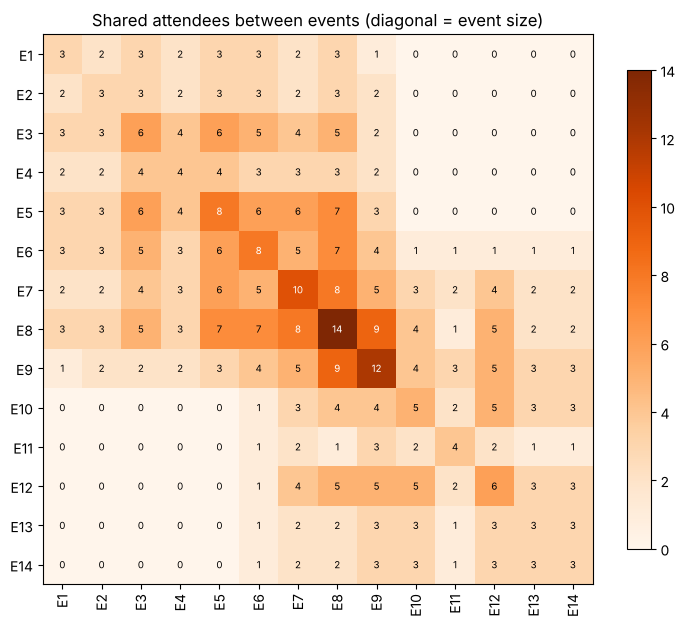

In [ ]:
E = bipartite.weighted_projected_graph(G, events)    # weight is number of shared women
print(f"Event projection: {E.number_of_edges()} ties out of {14*13//2} possible (density {nx.density(E):.2f})")

never = [(u, v) for i, u in enumerate(events) for v in events[i+1:] if not E.has_edge(u, v)]
print(f"Event pairs with NO woman in common: {len(never)}")
print("  ", ", ".join(f"{u}-{v}" for u, v in never))

T = A.values.T @ A.values                         # events x events is number of shared women
T = pd.DataFrame(T, index=events, columns=events)

fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(T.values, cmap="Oranges")
ax.set_xticks(range(14)); ax.set_xticklabels(events, rotation=90)
ax.set_yticks(range(14)); ax.set_yticklabels(events)
for i in range(14):
    for j in range(14):
        ax.text(j, i, T.iat[i, j], ha="center", va="center", fontsize=7,
                color="white" if T.iat[i, j] >= 8 else "black")
ax.set_title("Shared attendees between events (diagonal = event size)")
plt.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); plt.show()

### 4a. Which group does each event belong to?
Using the women's groups from Section 3b, I count how many attendees of each event came from each group. An event attended almost only by one group is that group's "private" event. An event with a mix is a shared, town-wide gathering.

In [ ]:
group_cols = [f"Group {i+1}" for i in range(len(comms))]
ev = pd.DataFrame({g: A.loc[[w for w in A.index if group_of[w] == i + 1]].sum() for i, g in enumerate(group_cols)})
ev["attendees"] = ev.sum(axis=1)
ev["share Group 1"] = ev["Group 1"] / ev["attendees"]

def label(s):
    if s >= 0.8: return "Group 1 event"
    if s <= 0.2: return "Group 2 event" if len(comms) == 2 else "Other groups' event"
    return "Mixed"
ev["type"] = ev["share Group 1"].apply(label)

ev["eigenvector"] = pd.Series(nx.eigenvector_centrality_numpy(E, weight="weight"))
ev["betweenness (women↔events graph)"] = pd.Series(bipartite.betweenness_centrality(G, women))[events]
ev

,Group 1,Group 2,attendees,share Group 1,type,eigenvector,betweenness (women↔events graph)
E1,3,0,3,1.00,Group 1 event,0.168,0.002
E2,3,0,3,1.00,Group 1 event,0.177,0.002
E3,6,0,6,1.00,Group 1 event,0.277,0.018
E4,4,0,4,1.00,Group 1 event,0.203,0.008
E5,8,0,8,1.00,Group 1 event,0.333,0.038
E6,6,2,8,0.75,Mixed,0.339,0.065
E7,6,4,10,0.60,Mixed,0.377,0.130
E8,7,7,14,0.50,Mixed,0.453,0.244
E9,3,9,12,0.25,Mixed,0.352,0.226
E10,0,5,5,0.00,Group 2 event,0.187,0.011


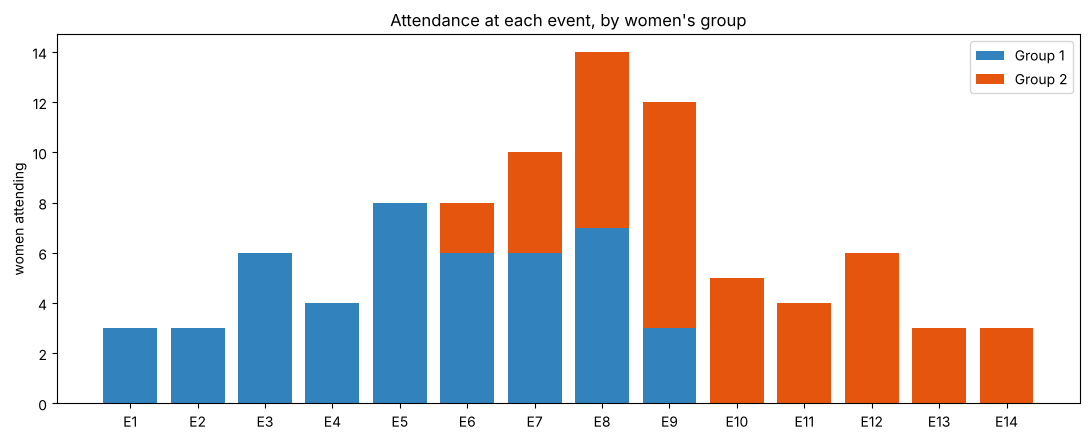

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4.5))
bottom = np.zeros(len(ev))
for i, g in enumerate(group_cols):
    ax.bar(ev.index, ev[g], bottom=bottom, color=palette[i], label=g)
    bottom += ev[g].values
ax.set_ylabel("women attending"); ax.set_title("Attendance at each event, by women's group")
ax.legend(); plt.tight_layout(); plt.show()

## 5. The whole picture: the attendance matrix reordered
Sorting the women by group (and by events attended within each group), and the events by the share of Group 1 attendees, turns the raw matrix into a picture of the network's structure.

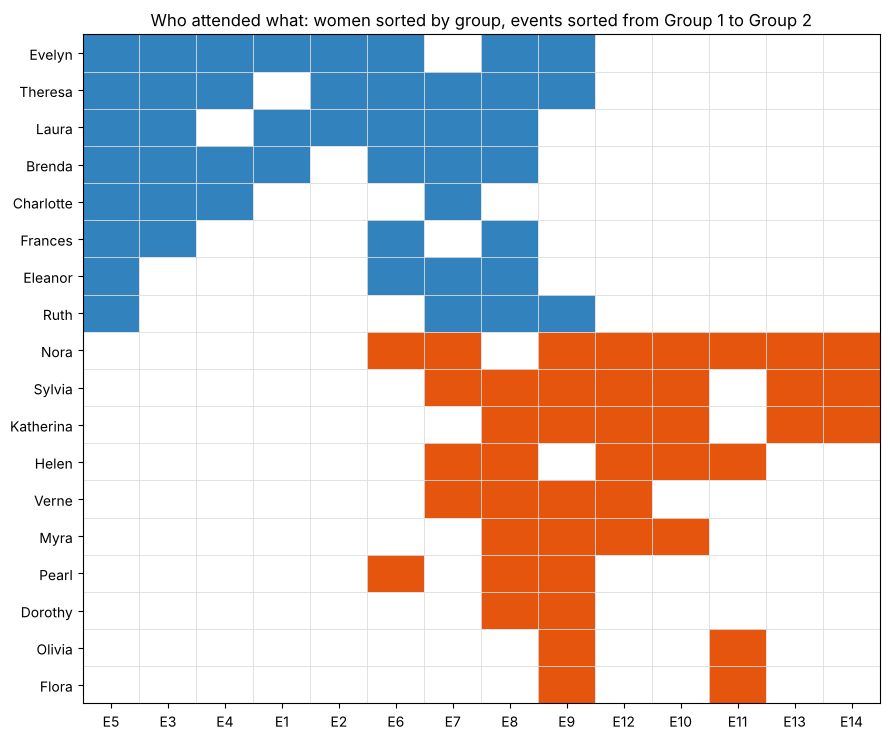

In [ ]:
row_order = sorted(A.index, key=lambda w: (group_of[w], -women_deg[w]))
col_order = ev.sort_values(["share Group 1", "attendees"], ascending=[False, False]).index
R = A.loc[row_order, col_order]

fig, ax = plt.subplots(figsize=(9, 7.5))
rgb = np.ones((*R.shape, 3))
for i, w in enumerate(R.index):
    c = np.array(plt.matplotlib.colors.to_rgb(palette[group_of[w] - 1]))
    rgb[i, R.loc[w].values == 1] = c
ax.imshow(rgb, aspect="auto")
ax.set_xticks(range(R.shape[1])); ax.set_xticklabels(R.columns)
ax.set_yticks(range(R.shape[0])); ax.set_yticklabels(R.index)
ax.set_xticks(np.arange(-.5, R.shape[1]), minor=True); ax.set_yticks(np.arange(-.5, R.shape[0]), minor=True)
ax.grid(which="minor", color="#dddddd", linewidth=0.6); ax.tick_params(which="minor", length=0)
ax.set_title("Who attended what: women sorted by group, events sorted from Group 1 to Group 2")
plt.tight_layout(); plt.show()

### 5a. The two-mode network drawn directly
For completeness, here is the original bipartite graph (as in the networkx example), with women on the left and events on the right, in the order of the reordered matrix.

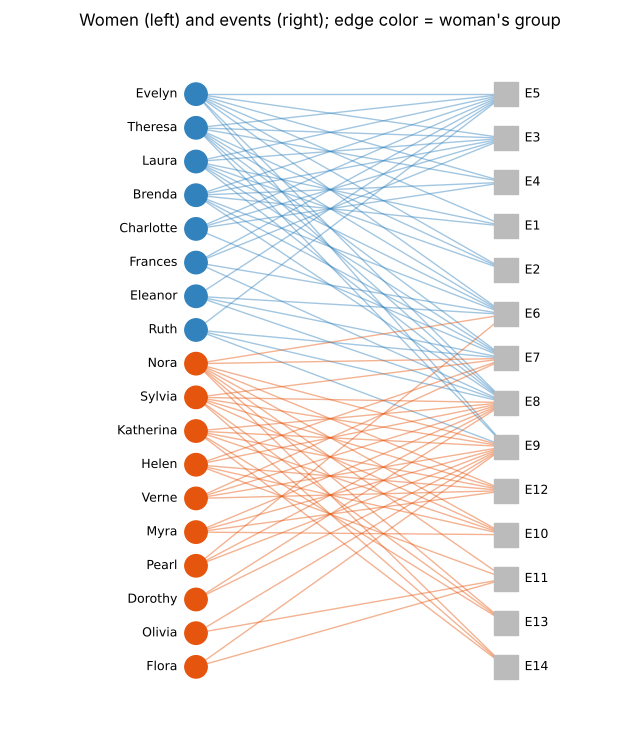

In [ ]:
pos_b = {w: (0, -i) for i, w in enumerate(row_order)}
pos_b.update({e: (1, -i * 17 / 13) for i, e in enumerate(col_order)})
Gs = nx.relabel_nodes(G, short)

plt.figure(figsize=(8, 9))
edge_colors = [palette[group_of[u if u in group_of else v] - 1] for u, v in Gs.edges()]
nx.draw_networkx_edges(Gs, pos_b, edge_color=edge_colors, alpha=0.45)
nx.draw_networkx_nodes(Gs, pos_b, nodelist=row_order, node_color=[palette[group_of[w]-1] for w in row_order], node_size=260)
nx.draw_networkx_nodes(Gs, pos_b, nodelist=list(col_order), node_color="#bbbbbb", node_shape="s", node_size=320)
nx.draw_networkx_labels(Gs, {k: (x - 0.06, y) for k, (x, y) in pos_b.items() if k in group_of},
                        labels={w: w for w in row_order}, horizontalalignment="right", font_size=9)
nx.draw_networkx_labels(Gs, {k: (x + 0.06, y) for k, (x, y) in pos_b.items() if k not in group_of},
                        labels={e: e for e in col_order}, horizontalalignment="left", font_size=9)
plt.xlim(-0.6, 1.4); plt.axis("off"); plt.title("Women (left) and events (right); edge color = woman's group")
plt.show()

## 6. Summary of results

In [ ]:
g1 = [w for w in A.index if group_of[w] == 1]; g2 = [w for w in A.index if group_of[w] == 2]
print("=" * 78)
print(f"Two-mode network: {len(women)} women, {len(events)} events, {G.number_of_edges()} attendances")
print(f"Women's projection density: {nx.density(W_simple):.2f}  |  events' projection density: {nx.density(E):.2f}")
print(f"Louvain groups: {len(comms)}  |  modularity {nx.community.modularity(W, comms, weight='weight'):.3f}")
print(f"Shared events: same group {np.mean(within):.2f} vs different groups {np.mean(between):.2f}")
top = cent.sort_values('shared events (weighted degree)', ascending=False)
print(f"Most connected woman: {top.index[0]} ({top.iloc[0]['shared events (weighted degree)']:.0f} shared events)")
br = cent.sort_values('betweenness (strong ties)', ascending=False)
print(f"Top broker (betweenness on strong ties): {br.index[0]} ({br.iloc[0]['betweenness (strong ties)']:.2f})")
print("Event types:", ev["type"].value_counts().to_dict())
print("Mixed events:", ", ".join(ev.index[ev["type"] == "Mixed"]))
print("=" * 78)

Two-mode network: 18 women, 14 events, 89 attendances
Women's projection density: 0.91  |  events' projection density: 0.73
Louvain groups: 2  |  modularity 0.152
Shared events: same group 2.88 vs different groups 1.70
Most connected woman: Theresa (57 shared events)
Top broker (betweenness on strong ties): Theresa (0.36)
Event types: {'Group 1 event': 5, 'Group 2 event': 5, 'Mixed': 4}
Mixed events: E6, E7, E8, E9


## 7. Conclusions

### (1) The women: two social circles inside one small social world
- **Everyone crossed paths, but not everyone spent time together.** In the simple projection, 139 of 153 possible pairs of women (91%) attended at least one event together, so "met at an event" tells us almost nothing. The number of shared events is what reveals the structure: most pairs shared only 1 or 2 events, while a few shared 6 or 7.
- **There are two distinct groups.** Louvain community detection on the weighted projection splits the women into two groups of 8 and 10. Women in the same group shared 2.88 events on average, compared with 1.70 across groups. Of the 46 strong ties (3+ shared events), only 7 cross between the groups. The reordered attendance matrix (Section 5) shows the split very clearly. The modularity is modest (0.15) because the large mixed events connect almost everyone, so the groups are separate circles within one town rather than isolated cliques.
- **Each group has a core and a periphery.**
    - Group 1's core is **Evelyn, Theresa, Laura and Brenda**: each attended 7 or 8 events, and every pair of them shared 6 or 7 events.
    - Group 2's core is **Nora, Sylvia and Katherina**, who shared 5 or 6 events with each other.
    - On the edges, **Dorothy, Olivia and Flora** attended only 2 events each and have no strong ties at all, and **Charlotte** has the fewest co-attendees (11 of 17).
- **Theresa is the most central woman.** She has the most shared events (57) and the highest eigenvector centrality (0.35), and she is the main broker in the strong-tie network (betweenness 0.36), followed by **Sylvia** (0.18) in Group 2. Each of them belongs firmly to her own group but also has many ties to the other.
- **Pearl and Ruth sit on the boundary.** About half of each woman's shared events are with the other group (52% for Pearl, 50% for Ruth). Pearl attended only mixed events (E6, E8, E9), and her only strong ties are with Evelyn and Theresa in Group 1, even though Louvain places her in Group 2. Her membership is ambiguous, and she is a well-known borderline case in reanalyses of this dataset.

### (2) The events: private gatherings and shared town-wide events
- **The events fall into three types.**
    - **E1–E5** were attended **only by Group 1** women.
    - **E10–E14** were attended **only by Group 2** women.
    - **E6–E9** were **mixed** and attended by both groups.
- **The two sets of private events never overlap.** Of the 91 pairs of events, 25 have no attendee in common, and they are exactly the pairs between E1–E5 and E10–E14. No woman attended both a Group 1 event and a Group 2 event.
- **E8 and E9 are the central events.** E8 drew 14 of the 18 women, 7 from each group, and has the highest eigenvector centrality (0.45) and betweenness (0.24). E9 drew 12 women (0.23 betweenness). These large gatherings are what hold the two circles together: without the four mixed events, the groups would have no contact at all.
- **Private events are smaller.** The group-only events had 3 to 8 attendees, while the mixed events had 8 to 14. This suggests a pattern of smaller, more exclusive gatherings within each circle, alongside a few larger community events that everyone attends.

### Overall
The two sides of the network explain each other: the women form two groups *because* they attend different sets of events, and the events split into two sets *because* they draw from different groups. This duality, where people are linked through events and events through people, is the reason two-mode networks are analyzed through both projections.

### Limitations
- Attending the same event does not necessarily mean friendship. Large events create many ties between women who may barely know each other, which is why the unweighted projection is so dense.
- The weighted projection counts every shared event equally. A shared small event probably says more about a relationship than a shared event with 14 people, and weighting ties by event size (for example, Newman's collaboration weighting) could sharpen the groups.
- With 18 women and 14 events, the boundary cases (Pearl, Ruth) depend on very few attendances, so their group membership should be treated as uncertain.